# Regresión: Lineal (OLS)

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from ModeladoRegresion import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_REG, VARIANTES, RUTA_FASE1_REG,
    cargar_split, separar_x_y_reg, crear_cv_reg, resumen_target, dispositivo_reg,
    ejecutar_fase1_reg, formatear_tabla_cv_reg, graficar_variantes, evaluar_smearing,
    elegir_variante, guardar_fase1_reg, formatear_hiperparametros,
    pruebas_ols, graficar_residuos_ols,
)

CLAVE = "lineal"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_reg(CLAVE),
}, name=NOMBRES_REG[CLAVE]).to_frame()

,Lineal (OLS)
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y_reg(df_train)
cv = crear_cv_reg(SEED)

resumen_target(y_train)

,Filas,Media,Mediana,DE,Asimetría,Ceros (%),BDI ≥ 14 (%)
Conjunto,,,,,,,
Train,3848,7.3,5.0,7.75,1.9,10.5,16.4


### Variantes del Target

Los predictores no se transforman (salvo el `StandardScaler` y el `OneHotEncoder(drop="first")` del Pipeline); lo que cambia es la escala en la que se entrena el target.

| Variante | Qué se entrena | Cómo se predice |
|---|---|---|
| **a) Nativo** | `bdi_total` sin transformar (pérdida cuadrática) | Predicción directa |
| **b) sqrt** | $\sqrt{y}$ | $\hat y = \frac{1}{n}\sum_i (\hat z + e_i)^2$ (smearing) |
| **c) log1p** | $\log(1+y)$ | $\hat y = \frac{1}{n}\sum_i \left(e^{\hat z + e_i} - 1\right)$ (smearing) |

En las tres, la predicción final se recorta a $[0, 63]$.

**Sesgo de retransformación.** Las transformaciones $\sqrt{y}$ y $\log(1+y)$ comprimen la cola derecha del BDI, y eso puede ayudar a modelos que tratan por igual los errores por encima y por debajo de la predicción. Pero el modelo aprende la media **en la escala transformada**, $E[g(y)\mid x]$, y al deshacer la transformación se obtiene $g^{-1}(E[g(y)\mid x])$, que **no** es $E[y\mid x]$. Como las inversas ($z^2$ y $e^z - 1$) son convexas, por la desigualdad de Jensen $g^{-1}(E[g(y)]) \le E[y]$: la predicción retransformada **subestima la media** del BDI, y más cuanto más dispersos son los residuos. Como el RMSE en puntos BDI premia acertar la media condicional, ese sesgo es un error sistemático.

**Corrección de smearing (Duan, 1983).** Sin suponer una distribución para los errores, se usan los residuos de entrenamiento en la escala transformada, $e_i = g(y_i) - \hat z_i$, como muestra de los errores posibles, y se promedia la retransformación sobre todos ellos:

$$\hat y = \frac{1}{n}\sum_{i=1}^{n} g^{-1}(\hat z + e_i)$$

Lo implementa `RegresorBDI` (en `src/ModeladoRegresion.py`): transforma $y$ en `fit`, calcula los residuos **solo con los datos de entrenamiento de cada fold** y en `predict` invierte con la corrección. Todas las métricas se calculan en puntos BDI, nunca en la escala transformada.

### Validación Cruzada por Variante

La regresión lineal no tiene hiperparámetros: cada variante se evalúa con `cross_validate` en los mismos folds y luego se reentrena con todo el train. El RMSE, el MAE y el R² se calculan siempre en puntos BDI.

In [4]:
tabla, pipelines, hiperparametros = ejecutar_fase1_reg(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo             RMSE = 6.9004 ± 0.4850  R² = 0.2009  (2 s)
✓ sqrt + smearing    RMSE = 6.9348 ± 0.4739  R² = 0.1927  (2 s)
✓ log1p + smearing   RMSE = 7.2537 ± 0.3909  R² = 0.1131  (2 s)


In [5]:
vista = formatear_tabla_cv_reg(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(1)
vista.rename(index=VARIANTES)

,RMSE,MAE,R²,Tiempo (s)
Variante,,,,
Nativo,6.900 ± 0.485,4.906 ± 0.187,0.201 ± 0.016,2.3
sqrt + smearing,6.935 ± 0.474,4.918 ± 0.192,0.193 ± 0.019,2.0
log1p + smearing,7.254 ± 0.391,5.039 ± 0.195,0.113 ± 0.064,1.8


La variante nativa obtiene el menor RMSE (6.900 ± 0.485) y el mayor R² (0.201 ± 0.016). sqrt queda muy cerca (6.935 ± 0.474, R² = 0.193), mientras que log1p empeora con claridad (7.254 ± 0.391, R² = 0.113) y es la más inestable en R² (± 0.064). El MAE sigue el mismo orden (4.906, 4.918 y 5.039).

Con un R² de 0.20, los seis predictores explican una quinta parte de la variabilidad del BDI. El RMSE de 6.9 puntos, frente a una desviación estándar del BDI de 7.75, indica que el modelo reduce en solo un 11% el error de predecir siempre la media.

La desviación del RMSE entre folds (≈ 0.48) es grande comparada con las diferencias entre variantes, porque los folds difieren en la dispersión del BDI. La del R², que se normaliza por esa dispersión, es mucho menor (≈ 0.016).

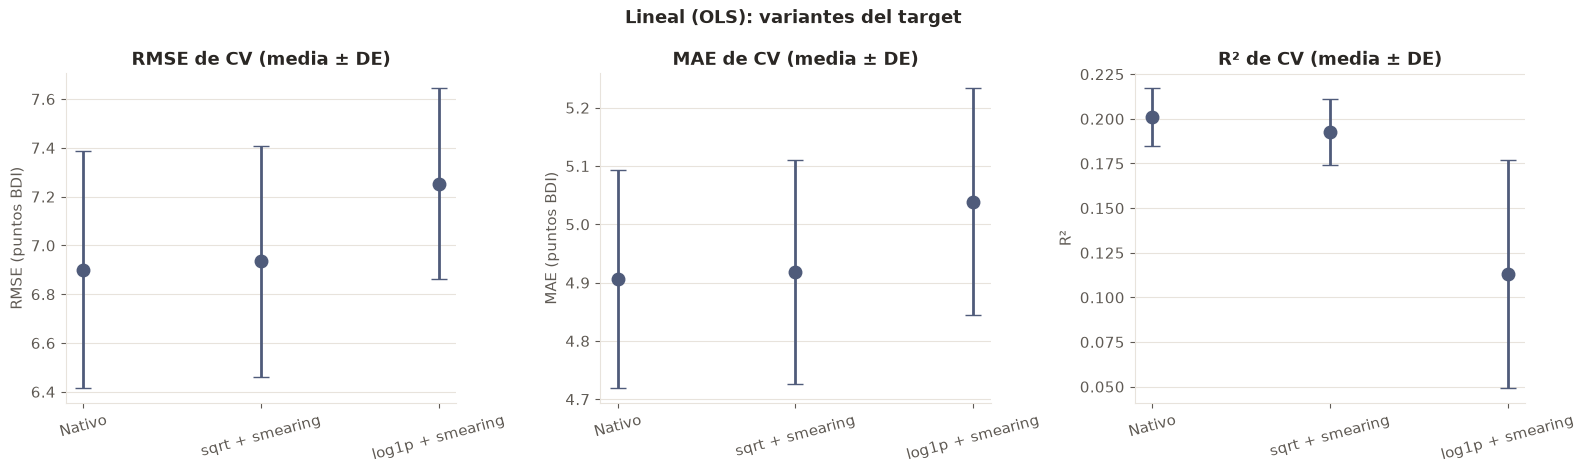

In [6]:
fig = graficar_variantes(tabla, NOMBRES_REG[CLAVE])
plt.show()

La gráfica confirma que el nativo y sqrt son prácticamente equivalentes en las tres métricas y que log1p es la peor. En la escala log1p, el modelo lineal supone efectos multiplicativos que, una vez retransformados, reproducen peor el BDI.

### Sesgo de Retransformación: Efecto del Smearing

Para ver el sesgo en la práctica se toma la mejor variante transformada y se calculan predicciones *out-of-fold* (mismos folds, solo train) **con y sin** la corrección de smearing. Sin la corrección, la media predicha debería quedar por debajo de la media real del BDI.

In [7]:
variante_t, tabla_smearing = evaluar_smearing(tabla, pipelines, X_train, y_train, cv)
tabla_smearing.round(3)

,Media,Sesgo medio,RMSE,MAE,R²
Out-of-fold (sqrt + smearing),,,,,
BDI real,7.302,0.000,NaN,NaN,NaN
Sin smearing,5.806,-1.496,7.110,4.673,0.157
Con smearing,7.286,-0.016,6.951,4.918,0.195


Sin smearing, la media predicha out-of-fold con sqrt es 5.81, 1.50 puntos por debajo de la media real (7.30). Ese es el sesgo de retransformación. Con la corrección, la media predicha pasa a 7.29 (sesgo de −0.02), el RMSE baja de 7.110 a 6.951 y el R² sube de 0.157 a 0.195.

El MAE, en cambio, empeora (de 4.673 a 4.918). Sin la corrección, la predicción se acerca a la mediana condicional, que es lo que minimiza el MAE en una distribución asimétrica. El smearing la lleva a la media, que es lo que minimiza el RMSE.

### Selección del Mejor Modelo Lineal (OLS)

Se elige la variante con **menor RMSE medio de CV**.

**Regla de empate:** si una variante más simple (nativo < sqrt < log1p) queda a menos de una desviación estándar de CV de la ganadora, se elige la más simple.

In [8]:
variante_ganadora, explicacion = elegir_variante(tabla)

pd.Series({
    "Variante ganadora": VARIANTES[variante_ganadora],
    "RMSE de CV": f"{tabla.loc[variante_ganadora, 'RMSE media']:.4f} ± {tabla.loc[variante_ganadora, 'RMSE DE']:.4f}",
    "MAE de CV": f"{tabla.loc[variante_ganadora, 'MAE media']:.4f} ± {tabla.loc[variante_ganadora, 'MAE DE']:.4f}",
    "R² de CV": f"{tabla.loc[variante_ganadora, 'R² media']:.4f} ± {tabla.loc[variante_ganadora, 'R² DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[variante_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_REG[CLAVE]).to_frame()

,Lineal (OLS)
Variante ganadora,Nativo
RMSE de CV,6.9004 ± 0.4850
MAE de CV,4.9064 ± 0.1872
R² de CV,0.2009 ± 0.0162
Hiperparámetros,sin tuning
Criterio,Se elige 'Nativo': tiene el menor RMSE medio de CV (6.9004 ± 0.4850) y ninguna opción más simple queda a menos de una desviación estándar (0.4850).


Gana la variante nativa por menor RMSE medio (6.9004), sin necesidad de la regla de empate. Es también la más interpretable: los coeficientes se leen directamente en puntos BDI.

### Guardado

In [9]:
ganador = guardar_fase1_reg(
    CLAVE, tabla, variante_ganadora, pipelines[variante_ganadora],
    hiperparametros[variante_ganadora], explicacion,
)
print(f"✓ Guardado en {RUTA_FASE1_REG / CLAVE}: resultados_cv.csv, ganador.json y {ganador['archivo']}")

✓ Guardado en /workspace/data/processed/modelado/regresion/fase1/lineal: resultados_cv.csv, ganador.json y lineal_nativo.joblib


## Pruebas de Hipótesis

Se ajusta la regresión lineal con statsmodels sobre **todo el train**, con el target nativo y los predictores preprocesados con el mismo `ColumnTransformer` ajustado en el train (numéricas estandarizadas, `sex` como indicadora `sex_Girl`), más la constante. Así, cada coeficiente numérico es el cambio en puntos BDI por cada desviación estándar del predictor. Nivel de significancia: α = 0.05.

Varias pruebas reutilizan `diagnosticar_regresion_lineal` (`src/LinearRegressionDiagnostics.py`): Shapiro-Wilk, Jarque-Bera, Breusch-Pagan, VIF y la influencia no cambian al estandarizar, porque los residuos y el leverage son los mismos.

> **Advertencia sobre el tamaño muestral.** Con n ≈ 3,800 las pruebas tienen tanta potencia que detectan desviaciones muy pequeñas, sin importancia práctica. Por eso cada prueba se complementa con un gráfico (Q-Q, residuos vs. ajustados) y con tamaños de efecto (coeficientes, R² ajustado, VIF), y la conclusión se basa en el conjunto, no solo en el p-valor.

In [10]:
pruebas = pruebas_ols(X_train, y_train)
pruebas["pruebas"]

,Hipótesis nula,Estadístico,p-valor,Conclusión (α = 0.05)
Prueba,,,,
Shapiro-Wilk,Los residuos son normales,0.867566,3.313583e-49,Se rechaza H0: los residuos no son normales
Jarque-Bera,Asimetría 0 y curtosis 3 (normalidad),4939.075510,0.000000e+00,Se rechaza H0: los residuos no son normales
Breusch-Pagan,Varianza de los residuos constante (homocedasticidad),193.919587,3.732568e-39,Se rechaza H0: hay heterocedasticidad
"RESET de Ramsey (ŷ², ŷ³)",La forma lineal está bien especificada,10.591438,2.587264e-05,Se rechaza H0: falta no linealidad o hay variables omitidas
F global,Todos los coeficientes (salvo la constante) son 0,166.653246,8.310504e-189,Se rechaza H0: al menos un predictor explica el BDI


Las cinco pruebas rechazan H0. La F global (166.7, p < 0.001) confirma que los predictores explican el BDI en conjunto, pero los supuestos de OLS no se cumplen. Los residuos no son normales (Shapiro-Wilk W = 0.868; Jarque-Bera = 4939), su varianza no es constante (Breusch-Pagan = 193.9) y la forma lineal no está del todo bien especificada (RESET F = 10.6, p < 0.001). Con n = 3,848 cualquier desviación sería significativa, así que su magnitud se juzga con los gráficos.

### Normalidad, Homocedasticidad y Especificación

El gráfico Q-Q compara los residuos estudentizados con los cuantiles de una normal. El de residuos vs. ajustados muestra si su dispersión cambia con el valor ajustado, y la curva LOWESS indica si queda alguna tendencia sin capturar.

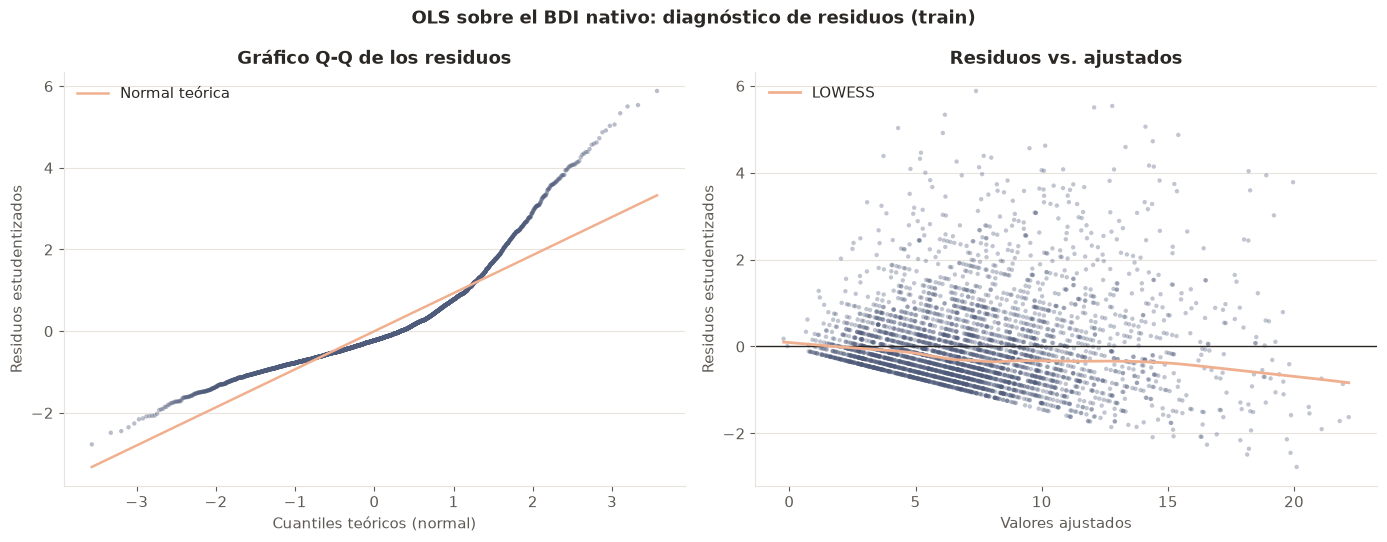

In [11]:
fig = graficar_residuos_ols(pruebas["modelo"], "OLS sobre el BDI nativo: diagnóstico de residuos (train)")
plt.show()

El gráfico Q-Q tiene forma de J. La cola izquierda es más corta que la normal (los residuos no bajan de ≈ −2.7, porque el BDI no puede ser negativo) y la derecha es mucho más larga (residuos estudentizados de hasta ≈ 6). No es una desviación pequeña detectada por el tamaño muestral, sino una asimetría marcada, heredada de la del BDI. Con n grande, el teorema central del límite hace que las pruebas t y F sigan siendo aproximadamente válidas, pero los intervalos de predicción basados en la normal no lo son.

En el gráfico de residuos vs. ajustados se ve un límite inferior en diagonal: cuando el BDI real es 0, el residuo es igual a menos el ajustado. Por encima, la dispersión crece con el valor ajustado, que es la heterocedasticidad típica de un conteo, donde la varianza aumenta con la media. La curva LOWESS desciende de 0 a ≈ −0.8 en los ajustados altos: el modelo sobreestima a quienes tienen más factores de riesgo. Eso coincide con el rechazo de la prueba RESET: la relación no es exactamente lineal en la escala del BDI, sino algo cóncava.

### Multicolinealidad (VIF)

Un VIF ≥ 5 indica que un predictor está muy explicado por los demás, lo que infla el error estándar de su coeficiente. `est_leisure_screen_hours` ya se excluyó por su redundancia con `screen_time_index` (Spearman r = 0.95).

In [12]:
pruebas["vif"].round(3)

,VIF,Conclusion,Umbral
Variable,,,
sleep_quality_index,1.152,Sin evidencia de multicolinealidad relevante,5
avg_sleep_hours,2.209,Sin evidencia de multicolinealidad relevante,5
midsleep_weekend_hours,6.885,Posible multicolinealidad relevante,5
social_jetlag_hours,5.051,Posible multicolinealidad relevante,5
screen_time_index,1.117,Sin evidencia de multicolinealidad relevante,5
sex_Girl,1.071,Sin evidencia de multicolinealidad relevante,5


`midsleep_weekend_hours` (6.9) y `social_jetlag_hours` (5.1) superan el umbral de 5. Ambas variables comparten información: el jetlag social es la diferencia entre el punto medio del sueño del fin de semana y el de entre semana. Los demás predictores tienen VIF entre 1.07 y 2.21. Esta colinealidad infla los errores estándar de esas dos variables y ayuda a explicar por qué ninguna es significativa (ver abajo), aunque no afecta a la capacidad predictiva del modelo.

### Observaciones Influyentes

Umbrales habituales: distancia de Cook > 4/n y leverage > 2p/n (p = parámetros con la constante). Lo preocupante son las observaciones que superan **ambos** umbrales: son atípicas en los predictores y además mueven el ajuste.

In [13]:
pruebas["influencia"]

,Valor
Indicador,
Umbral de distancia de Cook,0.001040
Umbral de leverage,0.003638
Observaciones con Cook alto,251.000000
Observaciones con leverage alto,259.000000
Observaciones con Cook y leverage altos,88.000000
Distancia de Cook maxima,0.018243
Leverage maximo,0.019245


251 observaciones (6.5%) superan el umbral de Cook (4/n = 0.0010) y 259 el de leverage (2p/n = 0.0036), pero solo 88 (2.3%) superan ambos. La distancia de Cook máxima es 0.018, muy lejos de 1, que es el valor a partir del cual una observación por sí sola cambiaría el ajuste. Hay muchos adolescentes con un BDI alto que el modelo no explica, pero ninguno domina los coeficientes.

### Significancia de los Coeficientes

Prueba t de cada coeficiente (H0: β = 0) y prueba F global (H0: todos los coeficientes, salvo la constante, son 0). El R² ajustado resume cuánto de la variabilidad del BDI explican los 6 predictores en conjunto.

In [14]:
display(pruebas["ajuste"])
pruebas["coeficientes"].round(4)

,OLS
Escala del target,nativa (puntos BDI)
n,3848
Predictores,6
R²,0.2066
R² ajustado,0.2053
F global,166.65
p-valor F,0.0


,Coeficiente,EE,Estadístico,p-valor,IC 2.5%,IC 97.5%,Significativo
Variable,,,,,,,
const,5.7403,0.1588,36.1497,0.0000,5.4289,6.0516,True
sleep_quality_index,2.2108,0.1195,18.5051,0.0000,1.9765,2.4450,True
avg_sleep_hours,-0.8857,0.1655,-5.3532,0.0000,-1.2101,-0.5613,True
midsleep_weekend_hours,0.4681,0.2921,1.6025,0.1091,-0.1046,1.0408,False
social_jetlag_hours,-0.0447,0.2502,-0.1789,0.8581,-0.5352,0.4457,False
screen_time_index,0.4480,0.1176,3.8086,0.0001,0.2174,0.6787,True
sex_Girl,3.1774,0.2304,13.7892,0.0000,2.7256,3.6292,True


El modelo explica el 20.7% de la variabilidad del BDI en el train (R² ajustado = 0.205). Cuatro coeficientes son significativos:

- **Calidad del sueño:** es el predictor más fuerte. Por cada desviación estándar más de `sleep_quality_index` (más alto = más problemas de sueño), el BDI esperado sube 2.21 puntos (IC 95%: 1.98 a 2.45).
- **Sexo:** las chicas puntúan 3.18 puntos más que los chicos (IC: 2.73 a 3.63), con las demás variables fijas.
- **Duración del sueño:** dormir una desviación estándar más reduce el BDI en 0.89 puntos (IC: −1.21 a −0.56).
- **Tiempo de pantalla:** una desviación estándar más lo aumenta en 0.45 puntos (IC: 0.22 a 0.68).

`midsleep_weekend_hours` (p = 0.109) y `social_jetlag_hours` (p = 0.858) no son significativos con los demás predictores en el modelo, en parte por la colinealidad entre ellos. La constante (5.74) es el BDI esperado de un chico con todos los predictores numéricos en su media.

### Errores Estándar Robustos (HC3)

Si Breusch-Pagan detecta heterocedasticidad, los errores estándar de OLS no son fiables (los coeficientes sí siguen siendo insesgados). Se repite la tabla con errores estándar robustos HC3 y se marca si algún coeficiente cambia de conclusión.

In [15]:
if pruebas["coeficientes_hc3"] is not None:
    display(pruebas["coeficientes_hc3"].round(4))
    cambios = pruebas["coeficientes_hc3"]["Cambia la conclusión"]
    print(f"Coeficientes que cambian de conclusión con HC3: {', '.join(cambios[cambios].index) or 'ninguno'}")
else:
    print("Breusch-Pagan no rechaza la homocedasticidad: no hace falta corregir los errores estándar.")

,Coeficiente,EE OLS,EE HC3,p-valor OLS,p-valor HC3,Cambia la conclusión
Variable,,,,,,
const,5.7403,0.1588,0.1346,0.0000,0.0000,False
sleep_quality_index,2.2108,0.1195,0.1522,0.0000,0.0000,False
avg_sleep_hours,-0.8857,0.1655,0.1787,0.0000,0.0000,False
midsleep_weekend_hours,0.4681,0.2921,0.3067,0.1091,0.1269,False
social_jetlag_hours,-0.0447,0.2502,0.2672,0.8581,0.8670,False
screen_time_index,0.4480,0.1176,0.1194,0.0001,0.0002,False
sex_Girl,3.1774,0.2304,0.2305,0.0000,0.0000,False


Coeficientes que cambian de conclusión con HC3: ninguno


Los errores estándar HC3 cambian poco: el de `sleep_quality_index` sube de 0.120 a 0.152 y el de la constante baja de 0.159 a 0.135; los demás varían menos de 0.02. Ningún coeficiente cambia de conclusión, así que la heterocedasticidad no altera qué predictores son significativos.

### Diagnóstico en la Escala Transformada

Si la variante ganadora es sqrt o log1p, los supuestos de OLS se asumen en **esa** escala (es sobre ella que se ajusta el modelo). Se repiten los diagnósticos de residuos allí.

In [16]:
if ganador["transformacion"] is not None:
    pruebas_t = pruebas_ols(X_train, y_train, transformacion=ganador["transformacion"])
    display(pruebas_t["pruebas"])
    display(pruebas_t["ajuste"])
    fig = graficar_residuos_ols(pruebas_t["modelo"], f"OLS sobre {ganador['transformacion']}(BDI): diagnóstico de residuos (train)")
    plt.show()
else:
    print("La variante ganadora es la nativa: los diagnósticos de arriba ya están en su escala.")

La variante ganadora es la nativa: los diagnósticos de arriba ya están en su escala.


La variante ganadora es la nativa, así que los diagnósticos de arriba ya están en su escala.

### Conclusiones

- La regresión lineal con el target nativo es la mejor variante (RMSE de CV = 6.900 ± 0.485; R² = 0.201). sqrt es prácticamente equivalente y log1p, claramente peor.
- El smearing elimina el sesgo de retransformación: sin él, sqrt subestima la media del BDI en 1.5 puntos.
- Los supuestos de OLS no se cumplen: los residuos son asimétricos a la derecha y heterocedásticos, y la relación es algo cóncava. Aun así, las conclusiones sobre los coeficientes se mantienen con los errores estándar robustos HC3.
- Los predictores con efecto son la calidad del sueño (+2.2 puntos por DE), el sexo (+3.2 en las chicas), la duración del sueño (−0.9 por DE) y el tiempo de pantalla (+0.4 por DE). El punto medio del sueño del fin de semana y el jetlag social no aportan con los demás en el modelo y están correlacionados entre sí (VIF > 5).